## **Описание проекта: оценка рисков невозврата кредита**

В вашем распоряжении данные клиентов банка «Скрудж», которые планируют взять кредит. Вам необходимо выяснить, что из имеющихся данных влияет на своевременное погашение кредита и каким именно образом.

Исследование поможет в создании модели кредитного скоринга — системы для оценки способности потенциального заёмщика погасить свой кредит.

По каждому клиенту есть информация о его семейном положении, образовании, доходе и другие данные. Вам предстоит подготовить данные к анализу и исследовать их, в процессе отвечая на вопросы.

### Описание данных

- `children` — количество детей в семье;
- `days_employed` — сколько дней работает клиент;
- `dob_years` — возраст клиента;
- `education` — уровень образования клиента;
- `education_id` — идентификатор образования клиента;
- `family_status` — семейное положение клиента;
- `family_status_id` — идентификатор семейного положения клиента;
- `gender` — пол клиента;
- `income_type` — тип дохода клиента;
- `debt` — был ли у клиента когда-либо просрочен платёж по кредиту;
- `total_income` — ежемесячный доход;
- `purpose` — причина оформления кредита.




## Шаг 1. Выгрузка и анализ данных



Импортируем необходимые библиотеки

In [1]:
# Импортируйте библиотеки для работы
# с таблицами и графиками
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

Присвоение перменной данных из датасета


In [2]:
# Загрузите датасет в переменную df_raw или другую по вашему выбору.
# Он доступен по адресу <credit_scoring_eng.csv>
# а при работе на платформе по адресу /datasets/credit_scoring_eng.csv
df_raw = pd.read_csv('https://code.s3.yandex.net/datasets/credit_scoring_eng.csv')

Создание копии датасета


In [3]:
# При помощи метода .copy() скопируйте датасет
# для работы с ним в переменную df или другую
df = df_raw.copy()

Изучение общей информации о содержащихся данных


Выведем общую информацию по датасету и первые пять его строк


In [4]:
# Изучите общую информацию о датасете
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21525 entries, 0 to 21524
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   children          21525 non-null  int64  
 1   days_employed     19351 non-null  float64
 2   dob_years         21525 non-null  int64  
 3   education         21525 non-null  str    
 4   education_id      21525 non-null  int64  
 5   family_status     21525 non-null  str    
 6   family_status_id  21525 non-null  int64  
 7   gender            21525 non-null  str    
 8   income_type       21525 non-null  str    
 9   debt              21525 non-null  int64  
 10  total_income      19351 non-null  float64
 11  purpose           21525 non-null  str    
dtypes: float64(2), int64(5), str(5)
memory usage: 2.0 MB


In [5]:
df.head()

,children,days_employed,dob_years,education,education_id,family_status,family_status_id,gender,income_type,debt,total_income,purpose
0,1,-8437.673028,42,bachelor's degree,0,married,0,F,employee,0,40620.102,purchase of the house
1,1,-4024.803754,36,secondary education,1,married,0,F,employee,0,17932.802,car purchase
2,0,-5623.422610,33,Secondary Education,1,married,0,M,employee,0,23341.752,purchase of the house
3,3,-4124.747207,32,secondary education,1,married,0,M,employee,0,42820.568,supplementary education
4,0,340266.072047,53,secondary education,1,civil partnership,1,F,retiree,0,25378.572,to have a wedding



## Шаг 2. Предобработка данных



Изучим пропущенные значения в данных


In [6]:
df.isna().sum().sort_values(ascending=False)

days_employed       2174
total_income        2174
dob_years              0
children               0
education              0
education_id           0
family_status_id       0
family_status          0
gender                 0
income_type            0
debt                   0
purpose                0
dtype: int64

Пропуски присутствуют лишь в колонках, содержащих количество дней устройства и заработка. Пропуски могут быть связаны с тем,
что человек уже на пенсии или не имеет трудоустройства.

Проверим, какие виды статусов содержит колонка income_type

In [7]:
df['income_type'].unique()

<StringArray>
[                   'employee',                     'retiree',
                    'business',               'civil servant',
                  'unemployed',                'entrepreneur',
                     'student', 'paternity / maternity leave']
Length: 8, dtype: str

Проверим совпадают ли пропуски в обеих колонках и рассмотрим количество пропусков в категориях не имеющих трудоустройства относительно общего количества

In [8]:
(df[df['days_employed'].isna() & df['total_income'].isna()]).shape[0]

2174

Пропуски совпадают, поэтому будем обарабытвать данных сразу для двух колонок.Также проверим распределение пропусков по колонке income_type 

In [9]:
df.groupby('income_type').agg({'days_employed': lambda a: a.isna().sum()})

,days_employed
income_type,
business,508
civil servant,147
employee,1105
entrepreneur,1
paternity / maternity leave,0
retiree,413
student,0
unemployed,0


Как можно видеть значительная часть пропусков пренадлежит категории людей в отствке. Однако остальные пропуски находятся у занятых людей. Данные пропуски могут быть вызваны нежеланием сообщать о сумме своей зарплаты или невозможностью разглашения, например, как у госслужащих. Таким образом можно заменить пропуски в этой категории, например, на значение 0.

In [10]:
df.loc[df['days_employed'].isna(), ['days_employed', 'total_income']] = 0

In [11]:
df['days_employed'].isna().mean()

np.float64(0.0)

Процент пропусков от общего количества составил около восьми процентов. Удалять эти данные не будем, т.к. они могут пригодиться для дальнейшего анализа.

In [12]:
df['days_employed'].isna().sum()

np.int64(0)

Некоторые значения в колонке количества отработанных дней имеют отрицательное значение. Поменяем их на положительные.

In [13]:
df['days_employed'] = abs(df['days_employed'])


1. Изучите уникальные значения в столбцах с уровнем образования (`education`) и полом клиента (`gender`). 
2. Устраните неявные дубликаты и некорректные значения.



Для поиска дубликатов изучим уникальные значения в столбцах education и gender


In [14]:
df['education'].unique()

<StringArray>
[  'bachelor's degree', 'secondary education', 'Secondary Education',
 'SECONDARY EDUCATION',   'BACHELOR'S DEGREE',        'some college',
   'primary education',   'Bachelor's Degree',        'SOME COLLEGE',
        'Some College',   'PRIMARY EDUCATION',   'Primary Education',
     'Graduate Degree',     'GRADUATE DEGREE',     'graduate degree']
Length: 15, dtype: str

Как можно видеть в колонке education присутствуют повторяющиеся значения с разным написанием. Приведем все названия к одному формату.

In [15]:
df['education'] = df['education'].str.lower()
df['education'].unique()

<StringArray>
[  'bachelor's degree', 'secondary education',        'some college',
   'primary education',     'graduate degree']
Length: 5, dtype: str

In [16]:
df['gender'].unique()

<StringArray>
['F', 'M', 'XNA']
Length: 3, dtype: str

Как можно видеть пропуски здесь заполнены как XNA.

Проверим количество строк с незаполенным полом.

In [17]:
df[df['gender'] == 'XNA'].shape[0]

1

Строка всего одна, поэтому ее можно удалить.

In [18]:
df = df[df['gender'] != 'XNA']


1. Проверьте наличие дубликатов. Изучите дублированные данные, если они есть, и примите решение — удалять их или оставить.



Проверим наличие явных дубликатов и удалим их при наличии.


In [19]:
df.columns

Index(['children', 'days_employed', 'dob_years', 'education', 'education_id',
       'family_status', 'family_status_id', 'gender', 'income_type', 'debt',
       'total_income', 'purpose'],
      dtype='str')

In [20]:
df['purpose'].unique()

<StringArray>
[                   'purchase of the house',
                             'car purchase',
                  'supplementary education',
                        'to have a wedding',
                     'housing transactions',
                                'education',
                         'having a wedding',
      'purchase of the house for my family',
                          'buy real estate',
               'buy commercial real estate',
              'buy residential real estate',
             'construction of own property',
                                 'property',
                      'building a property',
                 'buying a second-hand car',
                        'buying my own car',
 'transactions with commercial real estate',
                   'building a real estate',
                                  'housing',
         'transactions with my real estate',
                                     'cars',
                       'to become educate

In [21]:
df['purpose'] = df['purpose'].replace(['construction of own property', 'building a property', 'housing', 'purchase of my own house', 'purchase of the house for my family',\
                                        'purchase of the house', 'housing transactions', 'buying property for renting out', 'housing renovation'], 'property')\
                            .replace(['supplementary education', 'getting an education', 'to get a supplementary education', 'getting higher education', 'profile education',\
                                      'university education', 'going to university', 'to become educated'], 'education')\
                            .replace(['car purchase', 'buying a second-hand car', 'buying my own car', 'cars', 'to own a car', 'purchase of a car', 'to buy a car', 'second-hand car purchase'], 'car')\
                            .replace(['buy real estate', 'buy commercial real estate', 'buy residential real estate', 'transactions with commercial real estate', 'building a real estate'\
                                      'transactions with my real estate', 'real estate transactions', 'transactions with my real estate', 'building a real estate'], 'real estate')\
                            .replace(['wedding ceremony', 'to have a wedding', 'having a wedding'], 'wedding')

In [22]:
df['purpose'].unique()

<StringArray>
['property', 'car', 'education', 'wedding', 'real estate']
Length: 5, dtype: str

In [23]:
df.duplicated().sum()

np.int64(316)

In [24]:
df = df.drop_duplicates()

In [25]:
print(f'На этапе предобработки было отфильтровано {(1 - len(df) / len(df_raw)):.2%} данных')

На этапе предобработки было отфильтровано 1.47% данных



## Шаг 3. Обработка выбросов и аномальных значений


### Рассмотрим распределение дохода


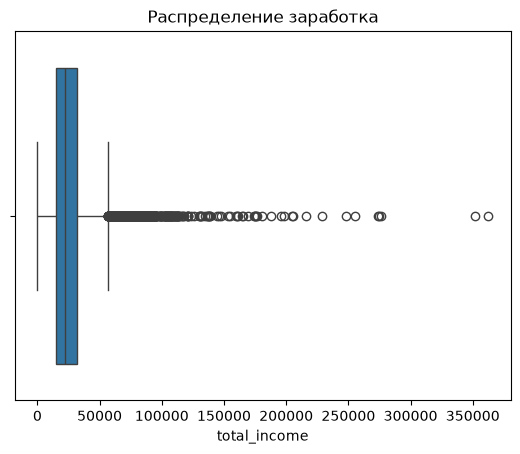

In [26]:
sns.boxplot(data=df, x='total_income')
plt.title('Распределение заработка')
plt.show()

В данных много выбросов, поэтому отфильтруем значения больше 99%.

In [27]:
df = df[df['total_income'] < df['total_income'].quantile(0.99)]

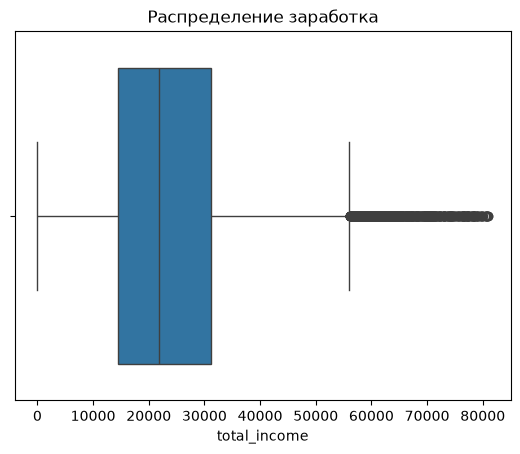

In [28]:
sns.boxplot(data=df, x='total_income')
plt.title('Распределение заработка')
plt.show()

Text(0.5, 1.0, 'Распределение заработка клиентов')

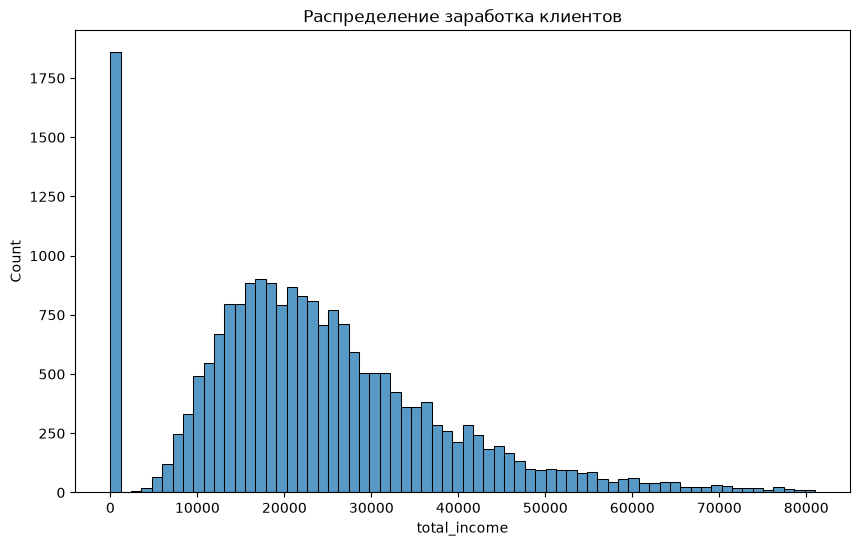

In [29]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='total_income')
plt.title('Распределение заработка клиентов')

### Распределение возраста клиентов

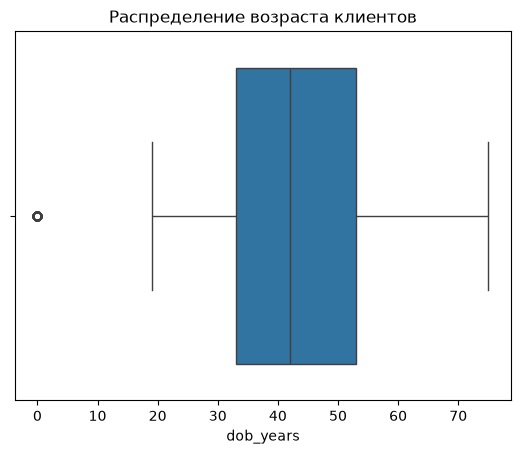

In [30]:
sns.boxplot(data=df, x='dob_years')
plt.title('Распределение возраста клиентов')
plt.show()

Как можно видеть выбросов в большую сторону не наблюдается, зато присутствуют анамально низкие значения равыные нулю. Это могут быть незаполненные данные.
Проверим количество таких данных.

In [31]:
df[df['dob_years'] < 18].shape[0] / len(df_raw)

0.004645760743321719

Таких данных меньше одного процента, поэтому отфильтруем их.

In [32]:
df = df[df['dob_years'] > 18]

### Анализ уникальных значений количества детей клиентов

In [33]:
df['children'].unique()

array([ 1,  0,  3,  2, -1,  4, 20,  5])

Изучим значения в этой колонке.

In [34]:
df['children'].value_counts()

children
 0     13696
 1      4708
 2      1999
 3       321
 20       75
-1        47
 4        40
 5         9
Name: count, dtype: int64

Как можно видеть в данных присутствуют аномалии. В данных есть отрицательное значение и нереалистичное значение в двадцать детей. Отфильтруем эти данные.

In [35]:
df = df[df['children'].isin(range(6))]

Проверим процент отфильтрованных данных на этапе предобработки.

In [36]:
print(f'На этапе предобработки было отфильтровано {(1 - len(df) / len(df_raw)):.2%} данных')

На этапе предобработки было отфильтровано 3.49% данных


В итоге предобработки было удалено 3.5% данных, что не сильно сказывается на итоговом анализе. Пропуски были также обработаны и заменены на кокретные значения.


## Шаг 4. Добавление новых данных




1. **Разделение клиентов на 5 категорий по уровню дохода:**
- Без дохода — люди без работы и с нулевым доходом.
- Очень низкий доход — люди, получающие ниже 14 процентиля от общего распределения дохода.
- Низкий доход — люди, получающие между 14 и 34 процентилями от общего распределения дохода.
- Средний доход — люди, получающие между 34 и 78 процентилями от общего распределения дохода.
- Высокий доход — люди, получающие больше 78 процентиля от общего распределения дохода.



### Разделим клиентов банка по категориям для дальнейшего удобства анализа различных категорий


Категории по доходности

In [37]:
cat_names = ['poor_income', 'low_income', 'avg_income', 'high_income']

df['total_income_groups'] = pd.qcut(df['total_income'], q=[0, 0.14, 0.34, 0.78, 1], labels=cat_names)

df['total_income_groups'] = df['total_income_groups'].cat.add_categories('no_income') #Добавляем категорию

df.loc[df['total_income'] == 0, 'total_income_groups'] = 'no_income'


1. Разделите клиентов на две категории по возрасту: до 40 лет и после. Сохраните результат в колонке `age_category`.



Категории по возрасту

In [38]:
df['age_category'] = pd.cut(df['dob_years'], bins=[18, 39, 120], labels=['under_40_y.o.', 'over_40_y.o.'])


1. Разделите клиентов на несколько категорий по количеству детей: без детей, от одного до двух, от трёх и больше. Сохраните результат в колонке `childrens_category`.



Категории по количеству детей


In [39]:
df['childrens_category'] = pd.cut(df['children'], bins=[-1, 0, 2, 10], labels=['any', 'one_or_two', 'more_than_two'])


## Шаг 5. Проведение исследовательского анализа данных




Задайте структуру наиболее объёмной части исследования. Исследуйте факторы: `Уровень дохода`, `Образование`, `Возраст`, `Количество детей`. Отличается ли распределение между должниками и нет? Исследуйте вопрос графически. Постройте сводную таблицу по каждому фактору и покажите, как часто встречаются должники в каждой группе клиентов. Выберите подходящую визуализацию и сравните 2 группы.



### Уровень дохода должников и не должников


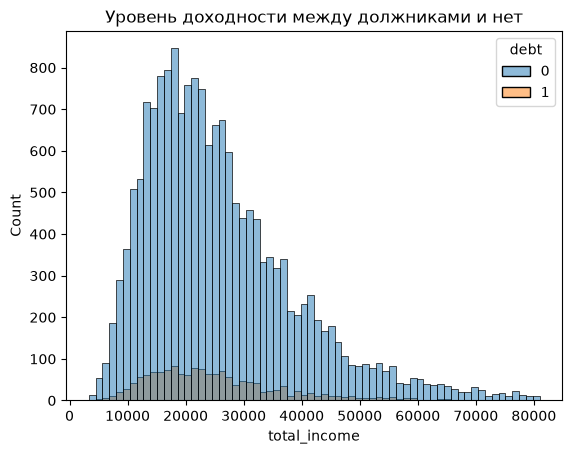

In [40]:
sns.histplot(data=df[df['total_income'] > 0], x='total_income', hue='debt')
plt.title('Уровень доходности между должниками и нет')
plt.show()

При рассмотрении всех должников и нет оба распределения имеют правоасимметричное распределение и не имеют выраженного смещения друг относительно друга. 

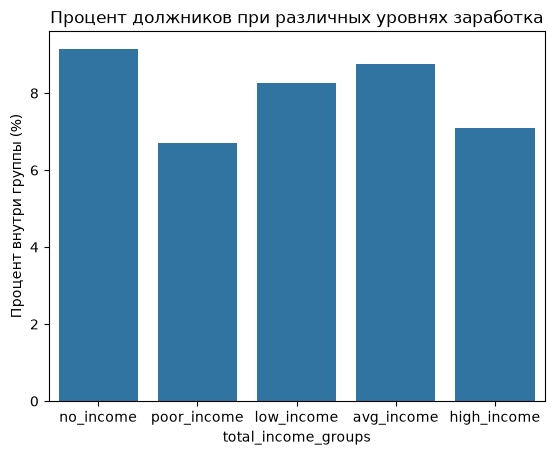

In [41]:
df_group_debt = df[df['debt'] == 1].groupby(['total_income_groups']).agg(count=('total_income_groups', 'count'))
df_group_without_debt = df[df['debt'] == 0].groupby(['total_income_groups']).agg(count=('total_income_groups', 'count'))
df_group = (df_group_debt / (df_group_without_debt + df_group_debt) * 100).reset_index()
edu_order = [
    'no_income', 
    'poor_income', 
    'low_income', 
    'avg_income', 
    'high_income'
]

df_group['total_income_groups'] = pd.Categorical(df_group['total_income_groups'], categories=edu_order, ordered=True)
df_group = df_group.sort_values('total_income_groups')
sns.barplot(data=df_group, x='total_income_groups', y='count')
plt.title('Процент должников при различных уровнях заработка')
plt.ylabel('Процент внутри группы (%)')
plt.show()

In [42]:
df_group

,total_income_groups,count
4,no_income,9.145346
0,poor_income,6.716418
1,low_income,8.257102
2,avg_income,8.763676
3,high_income,7.089716


При рассмотрении по выделенным группам таже не наблюдается разницы между группами.

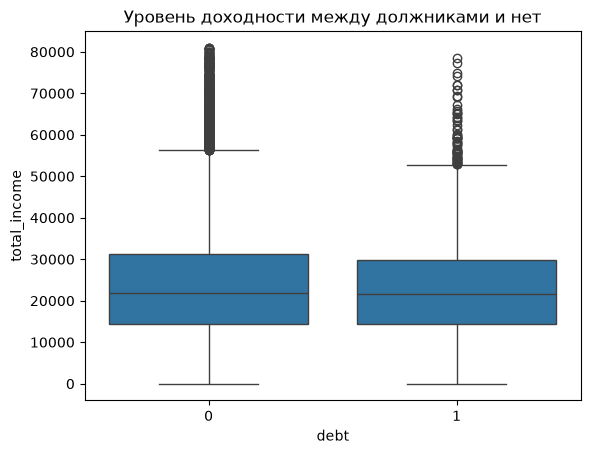

In [43]:
sns.boxplot(data=df, y='total_income', x='debt')
plt.title('Уровень доходности между должниками и нет')
plt.show()

In [44]:
print((df[df['debt'] == 0]['total_income'].mean() / df[df['debt'] == 1]['total_income'].mean() - 1))

0.03788438472768507


При сравнении на диаграмме с усами видно, что данные распределены примерно одинаково.

### Рассмотрим распределение в зависимости от образования.

### Распределение по возрасту

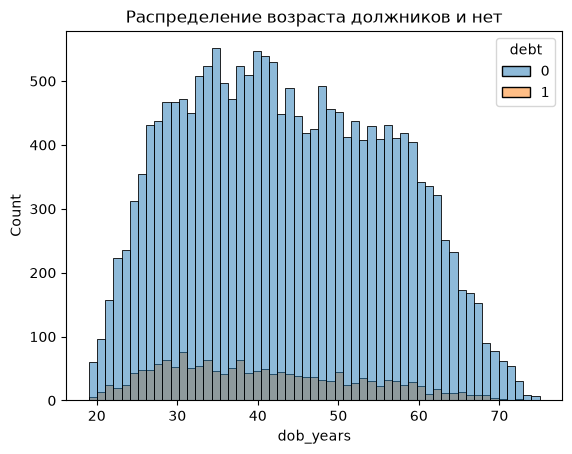

In [45]:
sns.histplot(data=df, x='dob_years', hue='debt', bins=55)
plt.title('Распределение возраста должников и нет')
plt.show()

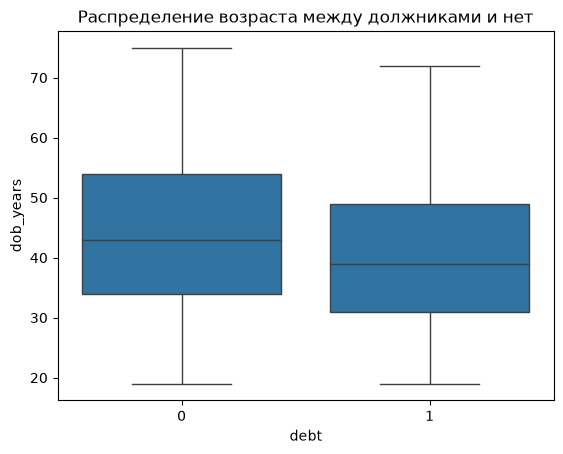

In [46]:
sns.boxplot(data=df, y='dob_years', x='debt')
plt.title('Распределение возраста между должниками и нет')
plt.show()

Должники в среднем моложе.

In [47]:
df_debt = df.groupby('age_category').agg(count_debt=('debt', 'sum'))
df_debt['count_without_debt'] = len(df) - df_debt['count_debt']
df_debt['percentage_of_debtors'] = (df_debt['count_debt'] / (df_debt['count_debt'] + df_debt['count_without_debt']) * 100)
probability = (df_debt.loc['under_40_y.o.', 'percentage_of_debtors'] / df_debt.loc['over_40_y.o.', 'percentage_of_debtors'] - 1)
df_debt

,count_debt,count_without_debt,percentage_of_debtors
age_category,,,
under_40_y.o.,890,19883,4.284408
over_40_y.o.,818,19955,3.937804


In [48]:
print(f'Вероятность того, что человек младше 40 лет окажется должником на {probability:.2%} выше, чем человек старше 40')

Вероятность того, что человек младше 40 лет окажется должником на 8.80% выше, чем человек старше 40


### Зависимость от количества детей

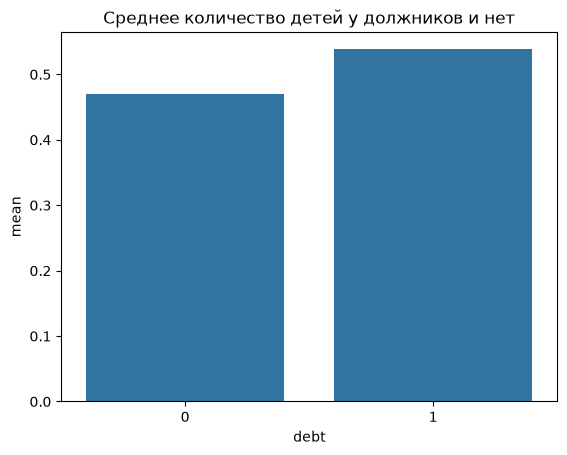

In [49]:
df_group = df.groupby(['debt']).agg(mean=('children', 'mean')).reset_index()
sns.barplot(data=df_group, x='debt', y='mean')
plt.title('Среднее количество детей у должников и нет')
plt.show()

In [50]:
df_debt = df.pivot_table(index='debt',
               columns='childrens_category',
               aggfunc='size')
df_debt['some'] = df_debt['one_or_two'] + df_debt['more_than_two']
df_debt = df_debt[['any', 'some']].T
df_debt['percentage_of_debtors'] = (df_debt[1] / (df_debt[1] + df_debt[0]) * 100)
df_debt

debt,0,1,percentage_of_debtors
childrens_category,,,
any,12649,1047,7.644568
some,6416,661,9.340116


Рассотрим распределение по выделенным возрастным группам.

In [51]:
df.pivot_table(index='debt',
               columns='total_income_groups',
               aggfunc='size')

total_income_groups,poor_income,low_income,avg_income,high_income,no_income
debt,,,,,
0,1000,3811,8339,4246,1669
1,72,343,801,324,168


In [52]:
df.pivot_table(index='debt',
               columns='education',
               aggfunc='size',
               fill_value=0)

education,bachelor's degree,graduate degree,primary education,secondary education,some college
debt,,,,,
0,4763,6,251,13382,663
1,269,0,31,1343,65


In [53]:
df.pivot_table(index='debt',
               columns='age_category',
               aggfunc='size')

age_category,under_40_y.o.,over_40_y.o.
debt,,
0,7751,11314
1,890,818


In [54]:
df.pivot_table(index='debt',
               columns='childrens_category',
               aggfunc='size')

childrens_category,any,one_or_two,more_than_two
debt,,,
0,12649,6077,339
1,1047,630,31


В группе после сорока лет наблюдается большее количество людей без долгов, а количество должников значительно не меняется.


***Проверка исследовательской гипотезы***: у клиентов с детьми более высокий уровень финансовой ответственности и, следовательно, более низкий риск просрочек по кредиту.



Чтобы подтвердить или опровергнуть данную гипотезу, сравним как меняется отношение должников и нет и увеличением числа детей в семье.


In [55]:
df_children = df.pivot_table(index='debt',
               columns='childrens_category',
               aggfunc='size')

df_children = df_children.loc[1] / df_children.loc[0] # Отношение количества не должников к должникам
#в зависимости от числа детей в семье

print(df_children)

childrens_category
any              0.082773
one_or_two       0.103670
more_than_two    0.091445
dtype: float64


Данные не подтверждают данную гипотезу, а наоборот говорят о небольшом увеличении отношения количества должников к людям без задолжностей с увиличением числа детей.


***Проверка исследовательской гипотезы***: одинокие мужчины с низким доходом чаще оказываются должниками, чем семейные мужчины со средним доходом.



In [56]:
df['family_status'].unique()

single_low = (df['total_income_groups'] == 'low_income') & (df['family_status'].isin(['widow / widower', 'divorced', 'unmarried']))
family_avg = (df['total_income_groups'] == 'avg_income') & (df['family_status'].isin(['married', 'civil partnership']))
man_debt = (df['gender'] == 'M') & (df['debt'] == 1)
man_no_debt = (df['gender'] == 'M') & (df['debt'] == 0)
chance_family = (df[family_avg & man_debt].shape[0] / df[family_avg & man_no_debt].shape[0])
chance_single = (df[single_low & man_debt].shape[0] / df[single_low & man_no_debt].shape[0])
print(f'Процент должников одиноких мужчин с низким доходом: {chance_single:.2%}')
print(f'Процент должников семейных мужчин со средним доходом: {chance_family:.2%}')
print(f'Разница составляет: {chance_single - chance_family:.2%}')

Процент должников одиноких мужчин с низким доходом: 18.08%
Процент должников семейных мужчин со средним доходом: 11.34%
Разница составляет: 6.74%


Данная гипотеза поддверждается. В среднем шанс, что семейный человек со средним доходом будет должником меньше чем у одинокого человека на 
6.74%. Такой результат весьма логичен и объясняется большей ответственностью перед своей семьей.


## Шаг 6. Выводы по проделанному анализу



Проведенный анализ выявил следующие взаимосвязи является ли клиент должником:
1. Уровень дохода не является определяющим фактором погашения кредита.
    - Самый высокий процент должников оказалася среди людей без дохода (9.15%), а среди людей имеющих заработок самый высокий процент оказался у людей со средним заработком (8.76%).
    - Таким образом люди не имеющие стабильного заработка более склонны к не погашению кредита, а люди с доходом имеют схожую вероятность по не погашению.
2. Возраст клиента с долгами в среднем моложе клиентов без долгов.
    - Вероятность того, что человек младше 40 лет окажется должником на 8.80% выше, чем человек старше 40.
    - Объясняется это тем, что люде страше 40 более склонны принимать правильные финансовые решения.
3. Семейное положение оказывает умеренное влияние:
    - Клиенты в браке и гражданском партнерстве демонстрируют на 10% - 12% лучшие показатели возврата кредитов.
    - Одинокие клиенты (вдовцы/вдовы, разведенные, не состоящие в отношениях) показывают более высокий уровень просрочек.
4. Образование имеет слабую корреляцию с кредитоспособностью:
    - Клиенты с высшим образованием демонстрируют немного лучшие показатели (разница 3 - 5%).
    - Однако эта разница не является статистически значимой при учете других факторов.
5. Наличие детей не подтвердило исходную гипотезу:
    - Клиенты с детьми имеют несколько более высокий уровень просрочек (9.21% против 7.54%).
    - Это может быть связано с дополнительными финансовыми обязательствами, связанными с содержанием детей.


---